In [1]:
import numpy as np
import networkx as nx
from scipy.linalg import eig
from heapq import heappush, heappop
from collections import defaultdict
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import time
import random

# -------------------------
# Funciones base
# -------------------------

def get_graph(edges, nodes):
    g = nx.Graph()
    g.add_edges_from(edges)
    g.add_nodes_from(nodes)
    return g


def matrix_prod_trace(A, B):
    n = len(A)
    diag_sum = 0
    for i in range(n):
        diag_sum += np.matmul(A[i, :], B[:, i])
    return diag_sum


def hash_p_stable(projection, r):
    if r <= 0:
        return 0
    b = np.random.uniform(0, r)
    return int(np.floor((projection + b) / r))


def get_erdos_renyi_graph(n, p):
    while True:
        g = nx.erdos_renyi_graph(n, p)
        if g.number_of_edges() > 0:
            return g

def get_adjacency(g, N):
    g = g.copy()
    g.remove_edges_from(nx.selfloop_edges(g))

    nodes_order = list(sorted(g.nodes()))

    A = nx.adjacency_matrix(
        g,
        nodelist=nodes_order,
        weight=None
    ).toarray()

    M = A.shape[0]
    A = np.pad(A, [(0, N - M), (0, N - M)], mode="constant")

    A = (A > 0).astype(float)
    np.fill_diagonal(A, 0)

    return A

def von_newmann_entropy(g):
    g = g.copy()
    g.remove_edges_from(nx.selfloop_edges(g))

    if g.number_of_edges() == 0:
        return 0.0

    L = nx.laplacian_matrix(g, weight=None).toarray().astype(float)
    rho = L / (2.0 * g.number_of_edges())

    eigvals = np.linalg.eigvalsh(rho)
    eigvals[eigvals < 1e-12] = 0.0
    eigvals = eigvals[eigvals > 1e-12]

    return float(-np.sum(eigvals * np.log2(eigvals)))


def aggregate(g1, g2, N):
    A1 = get_adjacency(g1, N)
    A2 = get_adjacency(g2, N)

    A = ((A1 + A2) > 0).astype(float)
    np.fill_diagonal(A, 0)
    
    return nx.from_numpy_array(A)


def js_divergence(g1, g2, N):
    h_mix = von_newmann_entropy(aggregate(g1, g2, N))
    h_avg = (von_newmann_entropy(g1) + von_newmann_entropy(g2)) / 2
    val = max(h_mix - h_avg, 0.0)
    return np.sqrt(val)

def get_bucket_id_for_graph(g, random_graphs, B, projection_ranges, N_pad):
    bucket_id = ""

    A = get_adjacency(g, N_pad)

    for k, erg in enumerate(random_graphs):
        A_er = get_adjacency(erg, N_pad)

        proj = matrix_prod_trace(A, A_er)

        min_proj, max_proj = projection_ranges[k]
        r = (max_proj - min_proj) / B

        hash_bin = hash_p_stable(proj, r)
        bucket_id += f"{hash_bin}_"

    return bucket_id

def aggregate_many(graph_list, N):
    """
    Agrega varios grafos como unión binaria de aristas.
    Si una arista aparece en al menos un grafo, queda como 1.
    """
    A_union = np.zeros((N, N))

    for g in graph_list:
        A_union += get_adjacency(g, N)

    A_union = (A_union > 0).astype(int)
    np.fill_diagonal(A_union, 0)

    return nx.from_numpy_array(A_union)

def quality(active, clusters, h_total=None, N_pad=None):
    """
    Calcula:

        q(C) = 1 - H(C) / h(A_agg)

    donde:

        H(C) = promedio de entropías de los clusters activos.

    active:
        set/list con los ids de clusters activos.

    clusters:
        diccionario {cluster_id: graph}

    h_total:
        h(A_agg). Si ya fue calculado, se pasa para evitar recomputarlo.

    N_pad:
        tamaño común de padding.
    """

    active = list(active)

    if len(active) == 0:
        return 0.0

    if N_pad is None:
        N_pad = max(g.number_of_nodes() for g in clusters.values())

    active_graphs = [clusters[i] for i in active]

    if h_total is None:
        A_agg_graph = aggregate_many(active_graphs, N_pad)
        h_total = von_newmann_entropy(A_agg_graph)

    if h_total <= 1e-12:
        return 0.0

    H_C = np.mean([
        von_newmann_entropy(g)
        for g in active_graphs
    ])

    q = 1.0 - (H_C / h_total)

    return float(q)

def refill_heap_global(active, clusters, N_pad):
    """
    Si no hay pares candidatos dentro de buckets,
    construye un heap global con todos los clusters activos.
    """
    heap = []
    active_list = list(active)

    for a in range(len(active_list)):
        for b in range(a + 1, len(active_list)):
            i = active_list[a]
            j = active_list[b]

            dist = js_divergence(clusters[i], clusters[j], N_pad)
            heappush(heap, (dist, i, j))

    return heap

def has_bucket_candidates(bucket_members, active):
    for members in bucket_members.values():
        alive = [x for x in members if x in active]
        if len(alive) >= 2:
            return True
    return False

In [2]:

def generate_cycle_graph(n_nodes):
    return nx.cycle_graph(n_nodes)


def generate_star_graph(n_nodes):
    return nx.star_graph(n_nodes - 1)

def generate_cycle_star_dataset(
    n_cycles=500,
    n_stars=500,
    min_nodes=10,
    max_nodes=10,
    seed=42
):
    random.seed(seed)
    np.random.seed(seed)

    graphs = []
    labels = []

    for _ in range(n_cycles):
        n = random.randint(min_nodes, max_nodes)
        g = generate_cycle_graph(n)
        graphs.append(g)
        labels.append("cycle")

    for _ in range(n_stars):
        n = random.randint(min_nodes, max_nodes)
        g = generate_star_graph(n)
        graphs.append(g)
        labels.append("star")

    combined = list(zip(graphs, labels))
    random.shuffle(combined)

    graphs, labels = zip(*combined)

    return list(graphs), list(labels)

graphs, labels = generate_cycle_star_dataset(
    n_cycles=500,
    n_stars=500,
    min_nodes=10,
    max_nodes=10,
    seed=42
)

N_pad = max(g.number_of_nodes() for g in graphs)

In [3]:
def build_lsh_buckets(graphs, num_proj=5, B=40, p_er=0.8):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    bucket_ids = [""] * num_graphs
    random_graphs = []
    projection_ranges = []

    for k in tqdm(range(num_proj), desc="LSH projections"):
        erg = get_erdos_renyi_graph(N_pad, p_er)
        random_graphs.append(erg)

        A_er = get_adjacency(erg, N_pad)

        projections = []

        for g in graphs:
            A = get_adjacency(g, N_pad)
            proj = matrix_prod_trace(A, A_er)
            projections.append(proj)

        min_proj = min(projections)
        max_proj = max(projections)

        projection_ranges.append((min_proj, max_proj))

        r = (max_proj - min_proj) / B

        for i in range(num_graphs):
            hash_bin = hash_p_stable(projections[i], r)
            bucket_ids[i] += f"{hash_bin}_"

    buckets = defaultdict(list)

    for i, bid in enumerate(bucket_ids):
        buckets[bid].append(i)

    return buckets, bucket_ids, random_graphs, projection_ranges

In [4]:
def hierarchical_bucket_heap_dynamic(
    graphs,
    buckets,
    bucket_ids,
    random_graphs,
    projection_ranges,
    B,
    epsilon=np.inf
):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    active = set(range(num_graphs))
    clusters = {i: graphs[i] for i in range(num_graphs)}

    cluster_bucket = {i: bucket_ids[i] for i in range(num_graphs)}

    bucket_members = defaultdict(set)
    for bid, indices in buckets.items():
        bucket_members[bid].update(indices)

    A_agg_graph = aggregate_many(
        [clusters[i] for i in active],
        N_pad
    )
    h_total = von_newmann_entropy(A_agg_graph)
    
    heap = []

    for bid, members in bucket_members.items():
        members = list(members)

        for a in range(len(members)):
            for b in range(a + 1, len(members)):
                i = members[a]
                j = members[b]

                dist = js_divergence(clusters[i], clusters[j], N_pad)
                heappush(heap, (dist, i, j))

    Z = []
    next_cluster_id = num_graphs
    global_mode = False

    while len(active) > 1:

        # Si LSH ya no produce candidatos, pasamos a clustering global normal
        if not global_mode and not has_bucket_candidates(bucket_members, active):
            global_mode = True
            heap = refill_heap_global(active, clusters, N_pad)

        if len(heap) == 0:
            if global_mode:
                heap = refill_heap_global(active, clusters, N_pad)
            else:
                break

        dist, i, j = heappop(heap)

        if i not in active or j not in active:
            continue

        # En modo LSH solo aceptamos pares dentro del mismo bucket
        if not global_mode and cluster_bucket[i] != cluster_bucket[j]:
            continue

        if dist > epsilon:
            break

        same_bucket = cluster_bucket[i] == cluster_bucket[j]

        old_bucket_i = cluster_bucket[i]
        old_bucket_j = cluster_bucket[j]

        new_id = next_cluster_id
        next_cluster_id += 1

        new_graph = aggregate(clusters[i], clusters[j], N_pad)

        active.remove(i)
        active.remove(j)

        bucket_members[old_bucket_i].discard(i)
        bucket_members[old_bucket_j].discard(j)

        clusters[new_id] = new_graph
        active.add(new_id)

        new_bucket_id = get_bucket_id_for_graph(
            new_graph,
            random_graphs=random_graphs,
            B=B,
            projection_ranges=projection_ranges,
            N_pad=N_pad
        )

        cluster_bucket[new_id] = new_bucket_id
        bucket_members[new_bucket_id].add(new_id)

        q = quality(
            active=active,
            clusters=clusters,
            h_total=h_total,
            N_pad=N_pad
        )

        Z.append([
            i,
            j,
            dist,
            q,
            new_id,
            new_bucket_id,
            same_bucket,
            global_mode
        ])

        if global_mode:
            for other in list(active):
                if other == new_id:
                    continue

                new_dist = js_divergence(
                    clusters[new_id],
                    clusters[other],
                    N_pad
                )

                heappush(heap, (new_dist, new_id, other))

        else:
            for other in list(bucket_members[new_bucket_id]):
                if other == new_id:
                    continue

                if other not in active:
                    continue

                new_dist = js_divergence(
                    clusters[new_id],
                    clusters[other],
                    N_pad
                )

                heappush(heap, (new_dist, new_id, other))

    return Z, clusters, active, bucket_members

In [5]:
def shclust_heap_dynamic(graphs, num_proj=5, B=40, epsilon=np.inf):
    buckets, bucket_ids, random_graphs, projection_ranges = build_lsh_buckets(
        graphs,
        num_proj=num_proj,
        B=B
    )

    Z, clusters, active, bucket_members = hierarchical_bucket_heap_dynamic(
        graphs=graphs,
        buckets=buckets,
        bucket_ids=bucket_ids,
        random_graphs=random_graphs,
        projection_ranges=projection_ranges,
        B=B,
        epsilon=epsilon
    )

    return Z, clusters, active, bucket_members, bucket_ids

In [6]:

start = time.time()

Z, clusters, active, bucket_members, bucket_ids = shclust_heap_dynamic(
    graphs,
    num_proj=2,
    B=5,
    epsilon=np.inf
)

time_lsh = time.time() - start

print("Tiempo LSH:", time_lsh)

# print("\nBucket IDs:")
# for i, bid in enumerate(bucket_ids):
#     print(f"Graph {i}: {bid}")

# print("\nMerges:")
# for row in Z:
#     print(row)

# print("\nFinal clusters:")
# print(clusters)

LSH projections: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00,  3.64it/s]


Tiempo LSH: 714.9842743873596


In [7]:
def plot_quality_by_merge(Z):
    df = pd.DataFrame(
        Z,
        columns=[
            "cluster_i",
            "cluster_j",
            "dist",
            "q",
            "new_cluster_id",
            "new_bucket_id",
            "same_bucket",
            "global_mode"
        ]
    )

    df["merge"] = range(1, len(df) + 1)

    # Encontrar máximo
    idx_max = df.shape[0] - 2 #df["q"].idxmax()
    x_max = df.loc[idx_max, "merge"]
    y_max = df.loc[idx_max, "q"]

    plt.figure(figsize=(8, 5))

    # Línea continua
    plt.plot(df["merge"], df["q"], color="black", linestyle="-")

    # Punto en el máximo
    plt.scatter(x_max, y_max, color="black" , zorder=5)

    #plt.xlabel("Merge")
    plt.ylabel("q(C)")
    #plt.title("Quality q(C) - hierarchical clustering normal")
    plt.grid(True)

    # # Opcional: anotar el punto máximo
    # plt.annotate(
    #     f"max={y_max:.3f}",
    #     (x_max, y_max),
    #     textcoords="offset points",
    #     xytext=(5,5)
    # )

    plt.show()

    return df

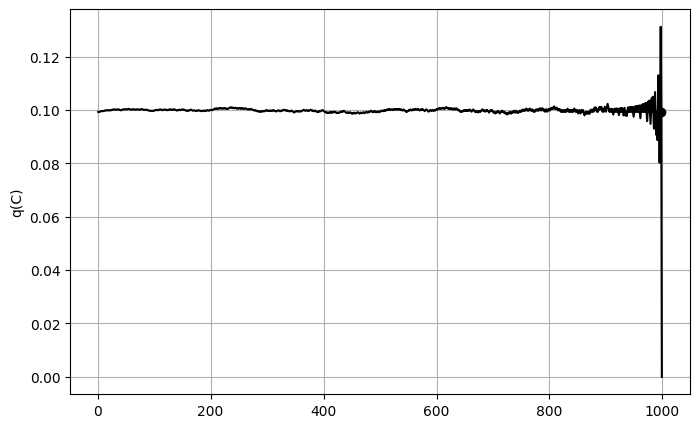

,cluster_i,cluster_j,dist,q,new_cluster_id,new_bucket_id,same_bucket,global_mode,merge
0,0,14,0.000000,0.099228,1000,7_0_,True,False,1
1,1,2,0.000000,0.099323,1001,13_0_,True,False,2
2,3,8,0.000000,0.099227,1002,8_0_,True,False,3
3,4,5,0.000000,0.099323,1003,13_0_,True,False,4
4,6,10,0.000000,0.099419,1004,13_0_,True,False,5
...,...,...,...,...,...,...,...,...,...
994,1990,1981,0.000000,0.080225,1994,8_0_,True,False,995
995,1992,1989,0.000000,0.099323,1995,13_0_,True,False,996
996,1991,1995,0.000000,0.131153,1996,13_0_,False,True,997
997,1993,1994,0.000000,0.099323,1997,7_0_,False,True,998


In [8]:
df_q = plot_quality_by_merge(Z)
df_q

# General

In [9]:
def hierarchical_clustering_heap(graphs, epsilon=np.inf):
    """
    Clustering jerárquico normal, sin buckets LSH.

    Usa:
        dist(g_i, g_j) = Jensen-Shannon distance

    Z guarda:
        [cluster_i, cluster_j, dist, q, new_cluster_id]
    """

    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    active = set(range(num_graphs))
    clusters = {i: graphs[i] for i in range(num_graphs)}

    # h(A_agg) fijo sobre todos los grafos originales
    A_agg_graph = aggregate_many(
        [clusters[i] for i in active],
        N_pad
    )
    h_total = von_newmann_entropy(A_agg_graph)

    heap = []

    # Inicializar heap con todos los pares globales
    active_list = list(active)

    for a in range(len(active_list)):
        for b in range(a + 1, len(active_list)):
            i = active_list[a]
            j = active_list[b]

            dist = js_divergence(clusters[i], clusters[j], N_pad)
            heappush(heap, (dist, i, j))

    Z = []
    next_cluster_id = num_graphs

    while len(active) > 1 and len(heap) > 0:
        dist, i, j = heappop(heap)

        # Lazy deletion
        if i not in active or j not in active:
            continue

        if dist > epsilon:
            break

        new_id = next_cluster_id
        next_cluster_id += 1

        new_graph = aggregate(clusters[i], clusters[j], N_pad)

        active.remove(i)
        active.remove(j)

        clusters[new_id] = new_graph
        active.add(new_id)

        q = quality(
            active=active,
            clusters=clusters,
            h_total=h_total,
            N_pad=N_pad
        )

        Z.append([
            i,
            j,
            dist,
            q,
            new_id
        ])

        # Calcular distancia del nuevo cluster contra todos los activos
        for other in list(active):
            if other == new_id:
                continue

            new_dist = js_divergence(
                clusters[new_id],
                clusters[other],
                N_pad
            )

            heappush(heap, (new_dist, new_id, other))

    return Z, clusters, active

In [10]:
start = time.time()

Z_normal, clusters_normal, active_normal = hierarchical_clustering_heap(
    graphs,
    epsilon=np.inf
)

time_normal = time.time() - start

print("Tiempo normal:", time_normal)

Tiempo normal: 2161.7913365364075


In [11]:

# print("\nMerges:")
# for row in Z_normal:
#     print(row)

# print("\nFinal clusters:")
# print(clusters_normal)

In [12]:
def plot_quality_normal(Z_normal):
    df = pd.DataFrame(
        Z_normal,
        columns=[
            "cluster_i",
            "cluster_j",
            "dist",
            "q",
            "new_cluster_id"
        ]
    )

    df["merge"] = range(1, len(df) + 1)

    # Encontrar máximo
    idx_max = df.shape[0] - 2 #df["q"].idxmax()
    x_max = df.loc[idx_max, "merge"]
    y_max = df.loc[idx_max, "q"]

    plt.figure(figsize=(8, 5))

    # Línea continua
    plt.plot(df["merge"], df["q"], color="black", linestyle="-")

    # Punto en el máximo
    plt.scatter(x_max, y_max, color="black" , zorder=5)

    #plt.xlabel("Merge")
    plt.ylabel("q(C)")
    #plt.title("Quality q(C) - hierarchical clustering normal")
    plt.grid(True)

    # # Opcional: anotar el punto máximo
    # plt.annotate(
    #     f"max={y_max:.3f}",
    #     (x_max, y_max),
    #     textcoords="offset points",
    #     xytext=(5,5)
    # )

    plt.show()

    return df

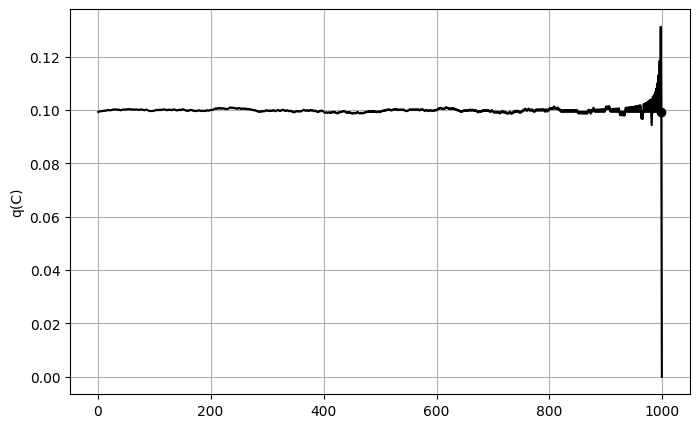

,cluster_i,cluster_j,dist,q,new_cluster_id,merge
0,0,3,0.000000,0.099228,1000,1
1,1,2,0.000000,0.099323,1001,2
2,4,5,0.000000,0.099419,1002,3
3,6,7,0.000000,0.099515,1003,4
4,8,12,0.000000,0.099419,1004,5
...,...,...,...,...,...,...
994,1990,1988,0.000000,0.118421,1994,995
995,1991,1989,0.000000,0.099323,1995,996
996,1994,1992,0.000000,0.131153,1996,997
997,1995,1993,0.000000,0.099323,1997,998


In [13]:
df_normal = plot_quality_normal(Z_normal)
df_normal

In [18]:
def compare_quality_curves(Z_lsh, Z_normal):
    df_lsh = pd.DataFrame(
        Z_lsh,
        columns=[
            "cluster_i",
            "cluster_j",
            "dist",
            "q",
            "new_cluster_id",
            "new_bucket_id",
            "same_bucket",
            "global_mode"
        ]
    )

    df_normal = pd.DataFrame(
        Z_normal,
        columns=[
            "cluster_i",
            "cluster_j",
            "dist",
            "q",
            "new_cluster_id"
        ]
    )

    df_lsh["merge"] = range(1, len(df_lsh) + 1)
    df_normal["merge"] = range(1, len(df_normal) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(df_normal["merge"], df_normal["q"], color="darkblue", linestyle="-", label="hclust")
    plt.plot(df_lsh["merge"], df_lsh["q"], color="red", linestyle="-.", label="shclust")
    #plt.xlabel("Merge")
    plt.ylabel("q(C)")
    #plt.title("Comparación de q(C): normal vs LSH")
    plt.legend()
    plt.grid(True)
    plt.show()

    return df_lsh, df_normal

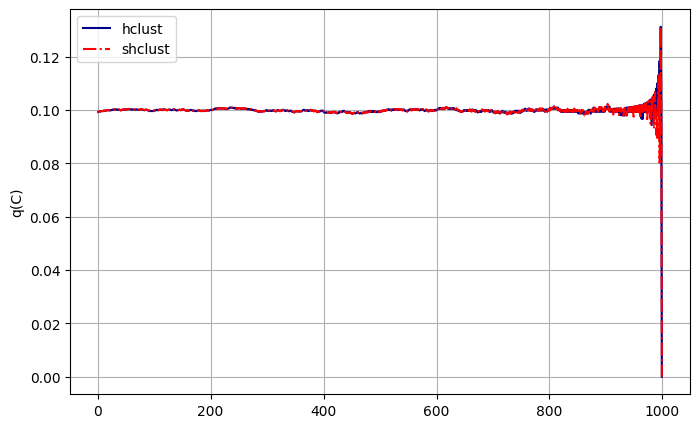

In [19]:
df_lsh, df_normal = compare_quality_curves(Z, Z_normal)

In [16]:
print("Tiempo normal:", time_normal)
print("Tiempo LSH:", time_lsh)
print("Speedup:", time_normal / time_lsh if time_lsh > 0 else np.inf)

Tiempo normal: 2161.7913365364075
Tiempo LSH: 714.9842743873596
Speedup: 3.0235508863306912
